# TSA Airport Complaint Analysis and Operational Insights

Integrate airport complaint data, build six visualizations, and develop operational recommendations.

**Tools:** Python, pandas, Matplotlib, Seaborn, Plotly

## 1. Setup and data loading

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import plotly.express as px
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data")
FILES = {
    "airport": DATA_DIR / "Complaints_By_Airport.xlsx",
    "category": DATA_DIR / "Complaints_By_Category.xlsx",
    "subcategory": DATA_DIR / "Complaints_By_Subcategory.xlsx",
    "lookup": DATA_DIR / "Airport_IATA_ICAO_Lookup.xlsx",
}

missing = [str(p) for p in FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing required files. Put the notebook beside the four Excel files:\n" + "\n".join(missing)
    )

airport = pd.read_excel(FILES["airport"], header=1)
category = pd.read_excel(FILES["category"])
subcategory = pd.read_excel(FILES["subcategory"])
lookup = pd.read_excel(FILES["lookup"], header=1)

print("Loaded shapes:")
for name, df in {"airport": airport, "category": category, "subcategory": subcategory, "lookup": lookup}.items():
    print(f"  {name:12s}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded shapes:
  airport     : 41,721 rows × 4 columns
  category    : 241,588 rows × 7 columns
  subcategory : 504,512 rows × 11 columns
  lookup      : 8,937 rows × 7 columns


## 2. Cleaning, validation, and integration

During the analysis, I preserved zero count records as these are useful for the monthly comparisons. I standardized dates and counts, removed duplicates, and joined the complaint data to the IATA airport lookup.

In [2]:
def clean_codes(series):
    return series.astype("string").str.strip().str.upper()

# Standardize key fields
for df in (airport, category, subcategory):
    df.columns = df.columns.astype(str).str.strip()
    df["airport"] = clean_codes(df["airport"])
    df["year_month"] = pd.to_datetime(df["year_month"], errors="coerce")
    df["count"] = pd.to_numeric(df["count"], errors="coerce").fillna(0)

lookup.columns = lookup.columns.astype(str).str.strip().str.lower()
lookup["iata"] = clean_codes(lookup["iata"])
lookup["latitude"] = pd.to_numeric(lookup["latitude"], errors="coerce")
lookup["longitude"] = pd.to_numeric(lookup["longitude"], errors="coerce")

# Prefer cleaned labels supplied in the source files
category["analysis_category"] = category["clean_cat"].fillna(category["category"]).astype("string").str.strip()
subcategory["analysis_category"] = subcategory["clean_cat"].fillna(subcategory["category"]).astype("string").str.strip()
subcategory["analysis_subcategory"] = subcategory["clean_subcat"].fillna(subcategory["subcategory"]).astype("string").str.strip().str.lstrip("*")

# Remove only exact duplicate records
before = {"airport": len(airport), "category": len(category), "subcategory": len(subcategory)}
airport = airport.drop_duplicates().copy()
category = category.drop_duplicates().copy()
subcategory = subcategory.drop_duplicates().copy()

airport_geo = airport.merge(
    lookup[["iata", "airport", "region_name", "country_code", "latitude", "longitude"]],
    left_on="airport", right_on="iata", how="left", suffixes=("_code", "_name")
)

unmatched_codes = sorted(airport_geo.loc[airport_geo["iata"].isna(), "airport_code"].dropna().unique())

validation = pd.DataFrame({
    "Dataset": ["Airport", "Category", "Subcategory"],
    "Rows before": [before["airport"], before["category"], before["subcategory"]],
    "Rows after exact deduplication": [len(airport), len(category), len(subcategory)],
    "Total complaint count": [airport["count"].sum(), category["count"].sum(), subcategory["count"].sum()]
})
display(validation)
print(f"Date range: {airport['year_month'].min():%Y-%m} through {airport['year_month'].max():%Y-%m}")
print(f"Unique complaint airport codes: {airport['airport'].nunique():,}")
print(f"Unmatched lookup codes: {len(unmatched_codes):,}")
print("First unmatched codes:", unmatched_codes[:20])

,Dataset,Rows before,Rows after exact deduplication,Total complaint count
0,Airport,41721,41721,1021281
1,Category,241588,241588,1021281
2,Subcategory,504512,503107,1020303


Date range: 2015-01 through 2024-01
Unique complaint airport codes: 448
Unmatched lookup codes: 5
First unmatched codes: ['CEF', 'JQF', 'JRB', 'NYL', 'UNV']


## 3. Snapshot of the Data

In [3]:
airport_totals = airport.groupby("airport", as_index=False)["count"].sum().sort_values("count", ascending=False)
category_totals = category.groupby("analysis_category", as_index=False)["count"].sum().sort_values("count", ascending=False)
subcat_totals = (subcategory.groupby(["analysis_category", "analysis_subcategory"], as_index=False)["count"]
                 .sum().sort_values("count", ascending=False))
monthly_totals = airport.groupby("year_month", as_index=False)["count"].sum().sort_values("year_month")

total_complaints = airport_totals["count"].sum()
top10_share = airport_totals.head(10)["count"].sum() / total_complaints if total_complaints else np.nan

snapshot = pd.DataFrame({
    "Metric": ["Total complaint count", "Airports represented", "Top airport", "Top category", "Top 10 airport share"],
    "Value": [
        f"{total_complaints:,.0f}",
        f"{airport['airport'].nunique():,}",
        f"{airport_totals.iloc[0]['airport']} ({airport_totals.iloc[0]['count']:,.0f})",
        f"{category_totals.iloc[0]['analysis_category']} ({category_totals.iloc[0]['count']:,.0f})",
        f"{top10_share:.1%}",
    ]
})
display(snapshot)

,Metric,Value
0,Total complaint count,"583,495"
1,Airports represented,448
2,Top airport,"LAX (24,794)"
3,Top category,"Expedited Passenger Screening Program (569,943)"
4,Top 10 airport share,34.9%


## Visual 1 — Monthly complaint volume (line chart)

In visual 1, it shows the trend of complaints. I used a three month moving average to reduce the month to month noise without removing the original values.

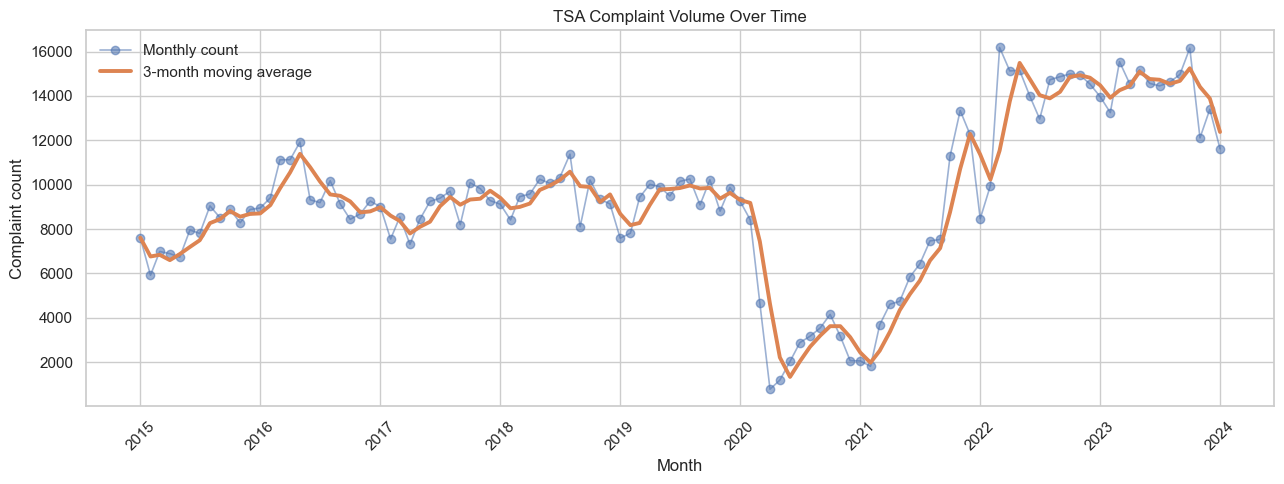

In [4]:
monthly_totals["3_month_average"] = monthly_totals["count"].rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly_totals["year_month"], monthly_totals["count"], marker="o", linewidth=1.2, alpha=.55, label="Monthly count")
ax.plot(monthly_totals["year_month"], monthly_totals["3_month_average"], linewidth=2.8, label="3-month moving average")
ax.set(title="TSA Complaint Volume Over Time", xlabel="Month", ylabel="Complaint count")
ax.legend(frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visual 2 — Leading complaint categories (bar chart)

In visual 2, it indetifies the operational problem areas where we can have the greatest impact.

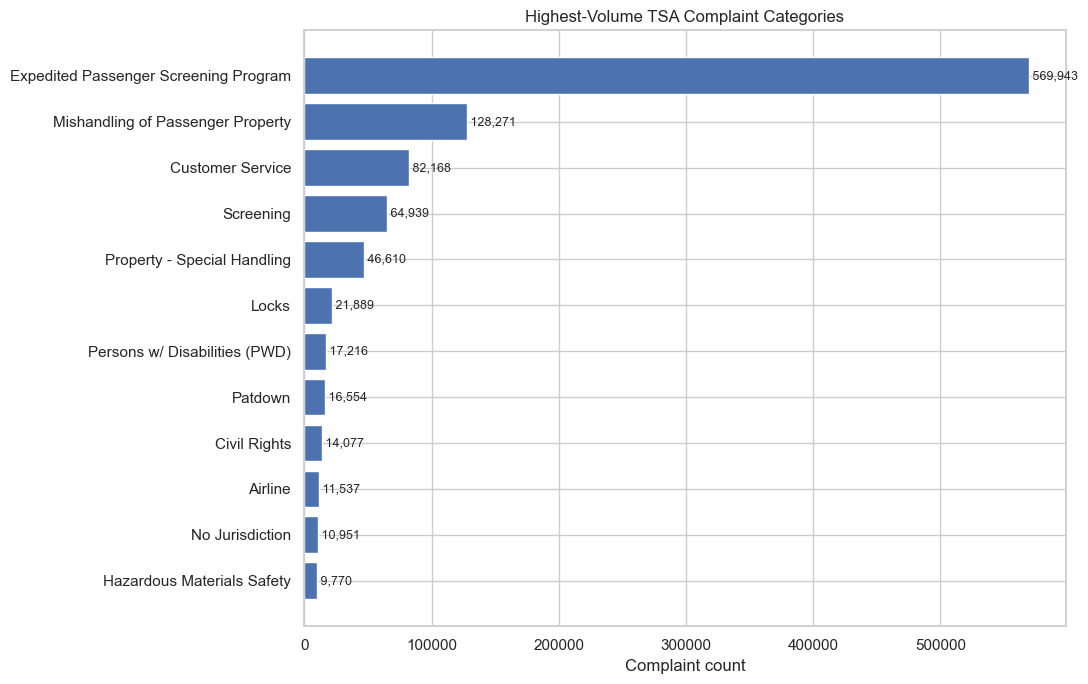

In [5]:
top_categories = category_totals.head(12).sort_values("count")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_categories["analysis_category"], top_categories["count"])
ax.set(title="Highest-Volume TSA Complaint Categories", xlabel="Complaint count", ylabel="")
for i, v in enumerate(top_categories["count"]):
    ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## Visual 3 — Airport/category concentration (heat map)

In visual 3, I used a heatmap to find which categories dominate within the highest volume airports. I used row percentages so we could compair each airports complaint mix even through they have different volume totals.

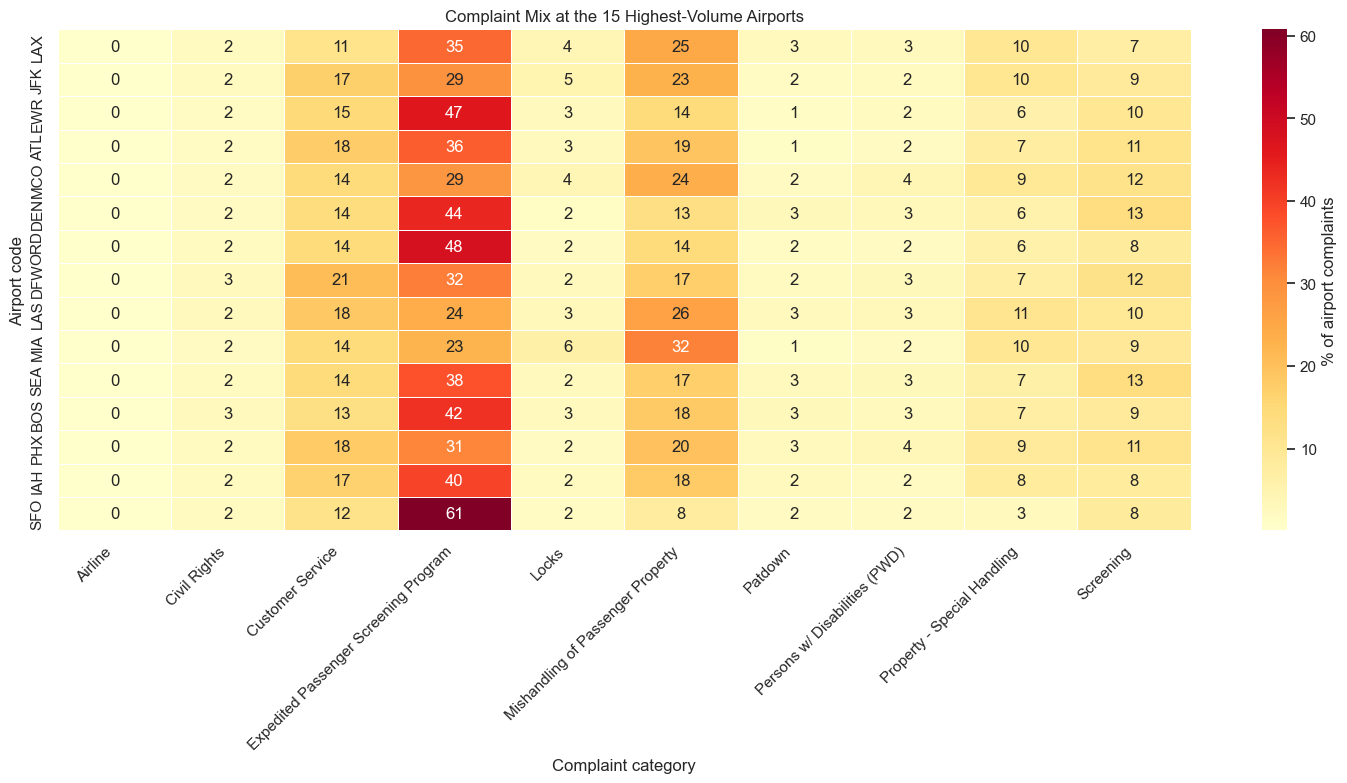

In [6]:
top_airports = airport_totals.head(15)["airport"].tolist()
top_cats = category_totals.head(10)["analysis_category"].tolist()

heat = (category[category["airport"].isin(top_airports) & category["analysis_category"].isin(top_cats)]
        .pivot_table(index="airport", columns="analysis_category", values="count", aggfunc="sum", fill_value=0))
heat_pct = heat.div(heat.sum(axis=1).replace(0, np.nan), axis=0) * 100
heat_pct = heat_pct.loc[[x for x in top_airports if x in heat_pct.index]]

plt.figure(figsize=(15, 8))
sns.heatmap(heat_pct, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=.4, cbar_kws={"label": "% of airport complaints"})
plt.title("Complaint Mix at the 15 Highest-Volume Airports")
plt.xlabel("Complaint category")
plt.ylabel("Airport code")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Visual 4 — Monthly distribution by airport (box plot)

The box plot compares typical monthly complaint volume and variability. Airports with high medians and long upper tails are candidates for both sustained intervention and surge planning.

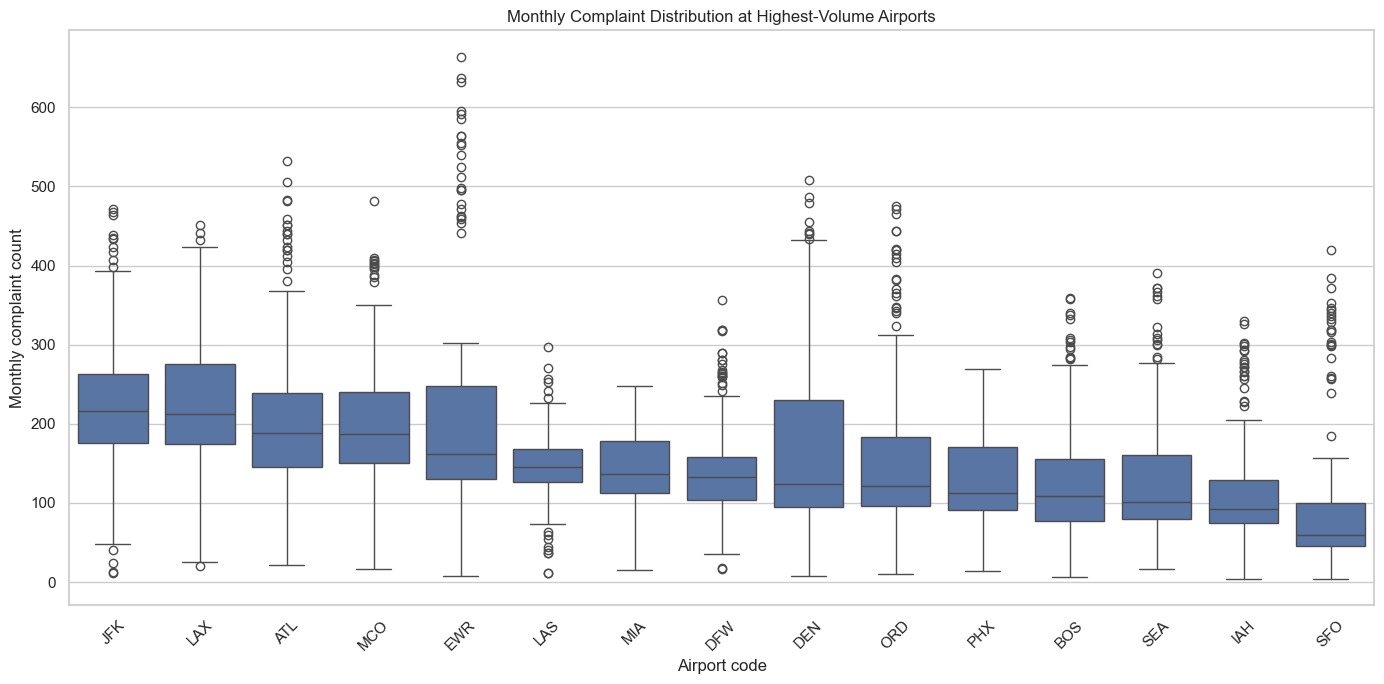

In [7]:
box_data = airport[airport["airport"].isin(top_airports)].copy()
order = (box_data.groupby("airport")["count"].median().sort_values(ascending=False).index)

plt.figure(figsize=(14, 7))
sns.boxplot(data=box_data, x="airport", y="count", order=order, showfliers=True)
plt.title("Monthly Complaint Distribution at Highest-Volume Airports")
plt.xlabel("Airport code")
plt.ylabel("Monthly complaint count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visual 5 — Spatial complaint concentration (spatial visual)

In visual 5, this is used to take marker sizes and show the total complaint volume on a map.

In [8]:
geo_totals = (airport.groupby("airport", as_index=False)["count"].sum()
              .merge(lookup[["iata", "airport", "region_name", "country_code", "latitude", "longitude"]],
                     left_on="airport", right_on="iata", how="left", suffixes=("_code", "_name"))
              .dropna(subset=["latitude", "longitude"]))
geo_totals = geo_totals[geo_totals["count"] > 0].copy()

if PLOTLY_AVAILABLE:
    fig = px.scatter_geo(
        geo_totals, lat="latitude", lon="longitude", size="count", color="count",
        hover_name="airport_name", hover_data={"airport_code": True, "count": ":,.0f", "latitude": False, "longitude": False},
        scope="usa", projection="albers usa", size_max=34,
        title="Geographic Concentration of TSA Complaint Volume"
    )
    fig.update_layout(margin=dict(l=0, r=0, t=55, b=0))
    fig.show()
else:
    fig, ax = plt.subplots(figsize=(13, 7))
    sizes = 20 + 500 * np.sqrt(geo_totals["count"] / geo_totals["count"].max())
    scatter = ax.scatter(geo_totals["longitude"], geo_totals["latitude"], s=sizes, c=geo_totals["count"], alpha=.65)
    ax.set(xlim=(-130, -65), ylim=(23, 51), title="Geographic Concentration of TSA Complaint Volume", xlabel="Longitude", ylabel="Latitude")
    plt.colorbar(scatter, ax=ax, label="Complaint count")
    plt.tight_layout()
    plt.show()

## Visual 6 — Pareto chart of complaint subcategories (custom visual)

In visual 6, I used a Pareto chart to combine the bar chart and a cumulative percentage line.

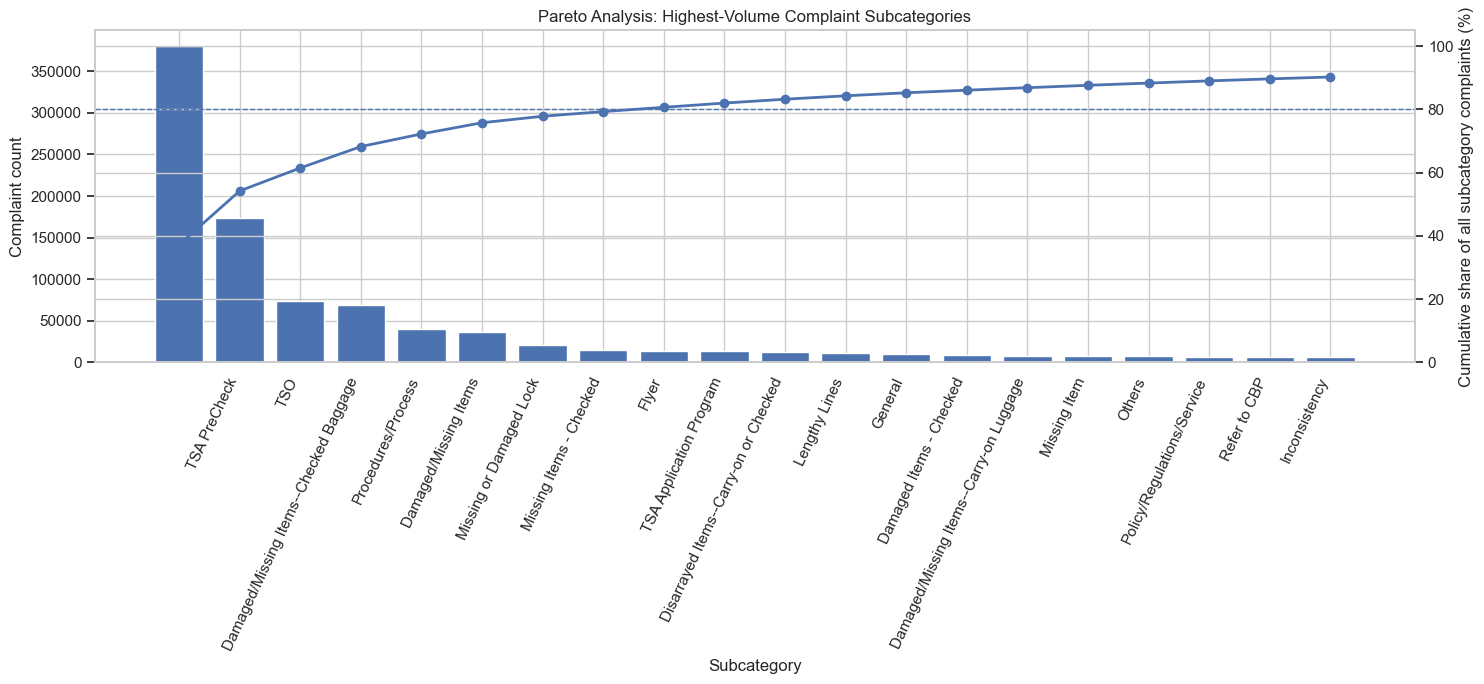

In [9]:
pareto = subcat_totals.head(20).copy()
pareto["label"] = pareto["analysis_subcategory"].fillna("Unknown")
pareto["cumulative_pct"] = pareto["count"].cumsum() / subcat_totals["count"].sum() * 100

fig, ax1 = plt.subplots(figsize=(15, 7))
ax1.bar(range(len(pareto)), pareto["count"])
ax1.set_ylabel("Complaint count")
ax1.set_xlabel("Subcategory")
ax1.set_xticks(range(len(pareto)))
ax1.set_xticklabels(pareto["label"], rotation=65, ha="right")
ax1.set_title("Pareto Analysis: Highest-Volume Complaint Subcategories")

ax2 = ax1.twinx()
ax2.plot(range(len(pareto)), pareto["cumulative_pct"], marker="o", linewidth=2)
ax2.axhline(80, linestyle="--", linewidth=1)
ax2.set_ylabel("Cumulative share of all subcategory complaints (%)")
ax2.set_ylim(0, 105)
plt.tight_layout()
plt.show()

## 4. Recommendations and Call to Action

In [10]:
# Identify the smallest set of subcategories that reaches approximately 80% of volume
pareto_all = subcat_totals.copy()
pareto_all["cumulative_share"] = pareto_all["count"].cumsum() / pareto_all["count"].sum()
cutoff_n = int((pareto_all["cumulative_share"] < .80).sum() + 1)
priority_subcats = pareto_all.head(cutoff_n)

print("RECOMMENDED ACTION")
print("Approve a 90-day complaint-reduction pilot at the five highest-volume airports.")
print("Use the category heat map to tailor each airport's intervention rather than applying one uniform solution.")
print(f"Track the first {cutoff_n} subcategories, which together account for about 80% of subcategory complaint volume.")
print("Report both raw complaint counts and complaints per 100,000 passengers once throughput data is added.")

print("\nTop five airports by complaint volume:")
display(airport_totals.head(5).reset_index(drop=True))
print("Priority subcategories through the 80% threshold:")
display(priority_subcats.reset_index(drop=True))

RECOMMENDED ACTION
Approve a 90-day complaint-reduction pilot at the five highest-volume airports.
Use the category heat map to tailor each airport's intervention rather than applying one uniform solution.
Track the first 9 subcategories, which together account for about 80% of subcategory complaint volume.
Report both raw complaint counts and complaints per 100,000 passengers once throughput data is added.

Top five airports by complaint volume:


,airport,count
0,LAX,24794
1,JFK,24677
2,EWR,24405
3,ATL,23591
4,MCO,22308


Priority subcategories through the 80% threshold:


,analysis_category,analysis_subcategory,count,cumulative_share
0,Expedited Passenger Screening Program,,379977,0.372416
1,Expedited Passenger Screening Program,TSA PreCheck,173413,0.542378
2,Customer Service,TSO,74213,0.615114
3,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,69026,0.682767
4,Screening,Procedures/Process,40653,0.722611
5,Mishandling of Passenger Property,Damaged/Missing Items,36191,0.758082
6,Locks,Missing or Damaged Lock,20888,0.778554
7,Property - Special Handling,Missing Items - Checked,15050,0.793305
8,Patdown,Flyer,13811,0.806841


## 5. Written summary (250–500 words)

We are creating this report for stakeholders, including TSA airport operations executives and customer experience leaders. The audience we are presenting this to understands the airport's operations but might not work directly with the complaint files, so this notebook will help show decision-ready patterns rather than technical modeling language. The main purpose is not just to report complaint totals but to secure approval for a 90-day improvement plan at some of the highest-volume airports. We will make changes based on the complaint categories and subcategories for each location.

I decided to use a Jupyter Notebook as a medium to combine data preparation, code, visualizations, and summary in a single document. The visuals I used were a monthly trend line, a category bar chart, an airport category heat map, an airport box plot, a spatial airport map, and a Pareto chart. The heat map, box plot, and spatial map were used to show complaint volumes. Combining all of these visuals. We can see the overall trend, the issues at hand, pinpoint them to specific airports, and create a call-to-action list by priority. 

I used the Gestalt principles to design this notebook. I wanted to maintain consistency across the chart titles, fonts, and labels. Alignment and shared axes support comparison, and avoiding excessive whitespace was beneficial in making this an effective notebook. Color was used primarily to convey importance rather than to make the notebook more appealing. Lastly, the text throughout the notebook is concise, chart sizes are appropriate for including labels, and categories are sorted to reduce searching.

With ethical considerations in mind, my analysis standardizes the airport codes, dates, and counts and uses simple category fields in the source, removing any duplicates. The most important limitation we are considering is that the dataset does not include passenger information. This causes raw complaint counts to fail to present complaint rates or evidence that a high-volume airport has worse customer service. The data is treated as credible because it comes from the assigned STA complaint count source and the IATA/ICAO lookup, while I also preserved the workflow from the source files.